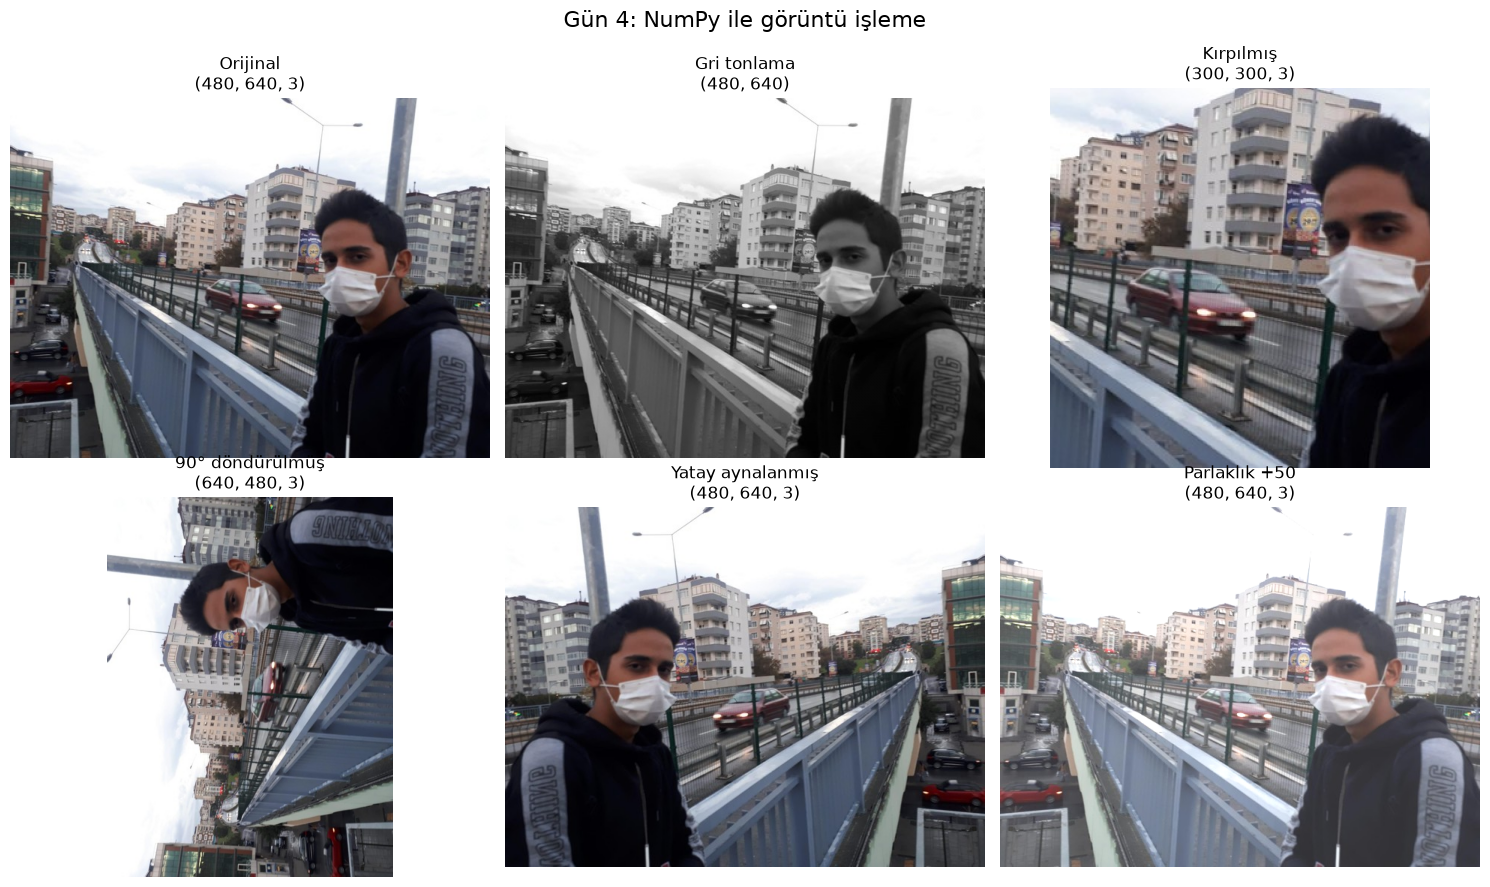

In [65]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Fotoğrafı yükle
img = np.array(Image.open("../gun03/kucuk/foto_018.jpg"))

# 1. Gri tonlama (ağırlıklı ortalama)
gri = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
gri = gri.round().astype(np.uint8)

# 2. Kırpma
kirpik = img[100:400, 200:500]

# 3. 90° döndürme
dondurulmus = np.rot90(img)

# 4. Yatay aynalama
aynali = img[:, ::-1]

# 5. Parlaklık +50 (taşmasız)
parlak = np.clip(img.astype(np.int16) + 50, 0, 255).astype(np.uint8)

# Gösterilecekler
sonuclar = [
    ("Orijinal", img),
    ("Gri tonlama", gri),
    ("Kırpılmış", kirpik),
    ("90° döndürülmüş", dondurulmus),
    ("Yatay aynalanmış", aynali),
    ("Parlaklık +50", parlak),
]

# Çizim
fig, axes = plt.subplots(2, 3, figsize=(15, 9), facecolor="none")

for ax, (baslik, goruntu) in zip(axes.flat, sonuclar):
    if goruntu.ndim == 2:
        ax.imshow(goruntu, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(goruntu)
    ax.set_title(f"{baslik}\n{goruntu.shape}")
    ax.axis("off")

fig.suptitle("Gün 4: NumPy ile görüntü işleme", fontsize=16)
plt.tight_layout()
plt.savefig("gun04_sonuclar.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [63]:
oran_once = (img == 255).mean() * 100
oran_sonra = (parlak == 255).mean() * 100

print(f"Önce: değerlerin %{oran_once:.1f} kadarı 255")
print(f"Sonra: değerlerin %{oran_sonra:.1f} kadarı 255")

Önce: değerlerin %16.6 kadarı 255
Sonra: değerlerin %25.5 kadarı 255


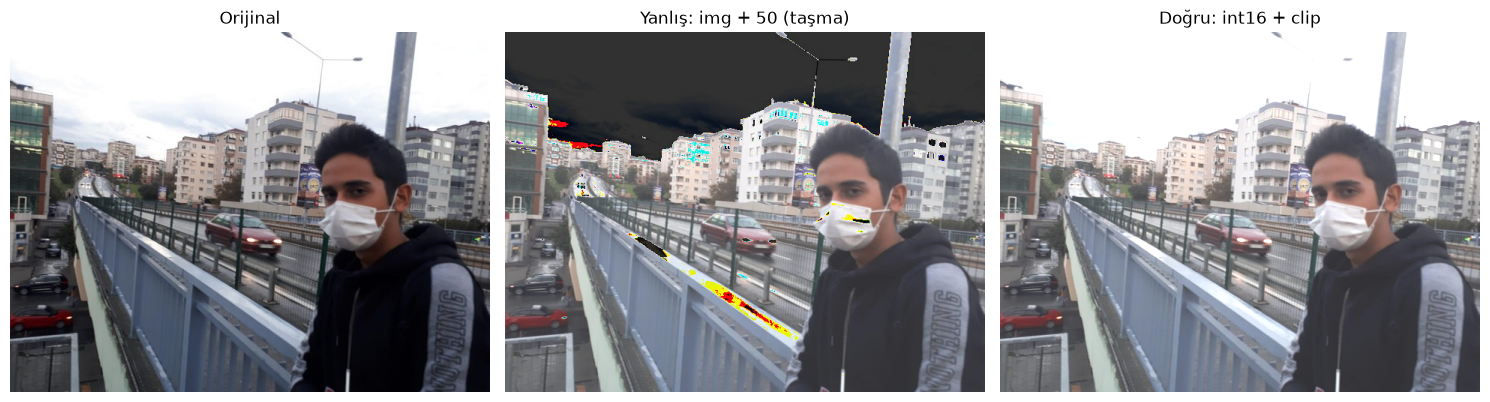

In [62]:
sonuclar = [
    ("Orijinal", img),
    ("Yanlış: img + 50 (taşma)", img + 50),
    ("Doğru: int16 + clip", parlak),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), facecolor="none")
for ax, (baslik, goruntu) in zip(axes, sonuclar):
    ax.imshow(goruntu)
    ax.set_title(baslik)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [61]:
def parlaklik(goruntu, miktar):
    gecici = goruntu.astype(np.int16) + miktar
    gecici = np.clip(gecici, 0, 255)
    return gecici.astype(np.uint8)


parlak = parlaklik(img, 50)

print("Orijinal en büyük / en küçük:", img.max(), img.min())
print("Parlak en büyük / en küçük:", parlak.max(), parlak.min())
print("dtype:", parlak.dtype)

Orijinal en büyük / en küçük: 255 0
Parlak en büyük / en küçük: 255 50
dtype: uint8


In [60]:
ornek_dogru = ornek.astype(np.int16) + 50
print("int16'da toplama:", ornek_dogru)

ornek_dogru = np.clip(ornek_dogru, 0, 255)
print("clip sonrası:", ornek_dogru)

ornek_dogru = ornek_dogru.astype(np.uint8)
print("uint8'e dönüş:", ornek_dogru)

int16'da toplama: [ 80 270 300]
clip sonrası: [ 80 255 255]
uint8'e dönüş: [ 80 255 255]


In [59]:
print(np.clip(np.array([-20, 100, 300]), 0, 255))

[  0 100 255]


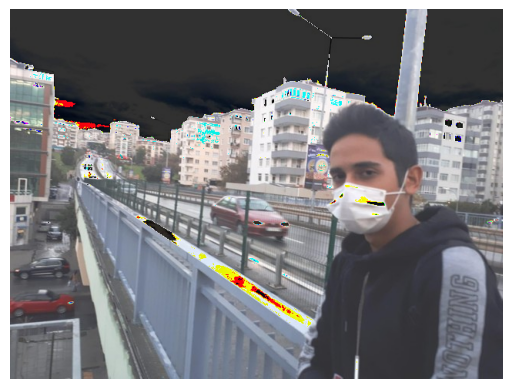

In [58]:
yanlis = img + 50

plt.imshow(yanlis)
plt.axis("off")
plt.show()

In [57]:
ornek = np.array([30, 220, 250], dtype=np.uint8)
print(ornek + 50)

[80 14 44]


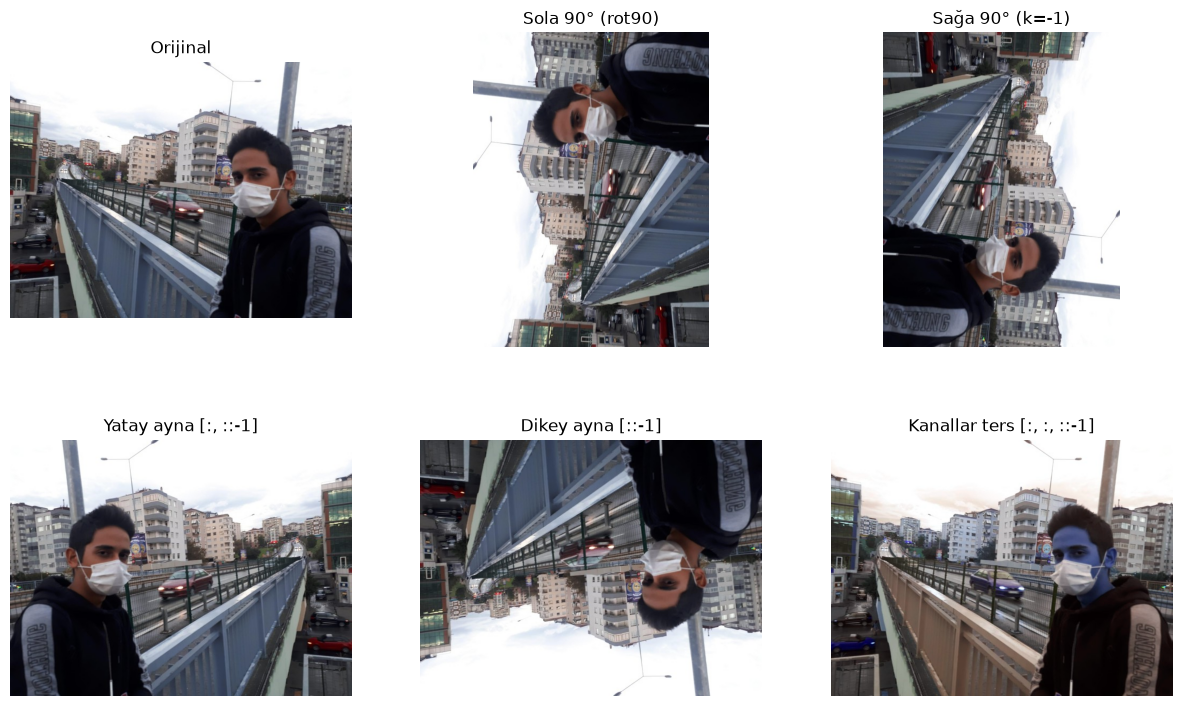

In [53]:
sonuclar = [
    ("Orijinal", img),
    ("Sola 90° (rot90)", np.rot90(img)),
    ("Sağa 90° (k=-1)", np.rot90(img, k=-1)),
    ("Yatay ayna [:, ::-1]", img[:, ::-1]),
    ("Dikey ayna [::-1]", img[::-1]),
    ("Kanallar ters [:, :, ::-1]", img[:, :, ::-1]),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (baslik, goruntu) in zip(axes.flat, sonuclar):
    ax.imshow(goruntu)
    ax.set_title(baslik)
    ax.axis("off")

plt.show()

Aynalı: (480, 640, 3)


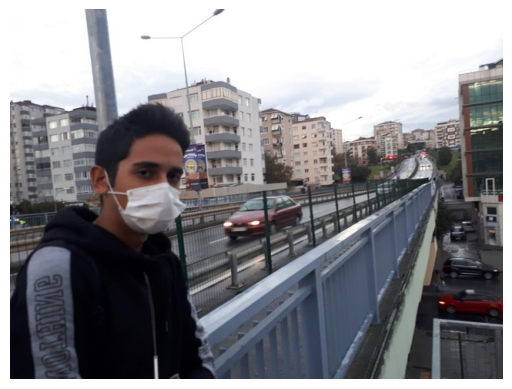

In [52]:
aynali = img[:, ::-1]

print("Aynalı:", aynali.shape)

plt.imshow(aynali)
plt.axis("off")
plt.show()

In [49]:
sayilar = np.array([10, 20, 30, 40, 50, 60])

print(sayilar[::2])     # [10 30 50]     → ikişer ikişer
print(sayilar[1::2])    # [20 40 60]     → 1'den başla, ikişer ikişer
print(sayilar[::-1])    # [60 50 40 30 20 10] → tersten

[10 30 50]
[20 40 60]
[60 50 40 30 20 10]


Orijinal: (480, 640, 3)
Döndürülmüş: (480, 640, 3)


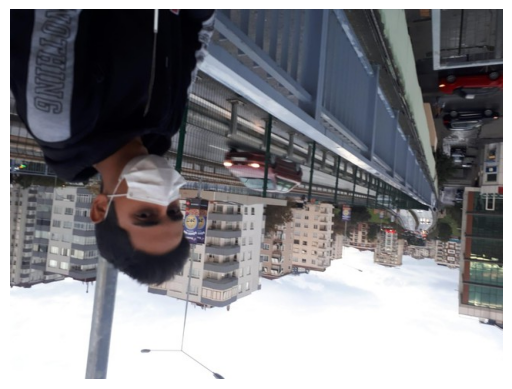

In [48]:
dondurulmus = np.rot90(img, k=2)

print("Orijinal:", img.shape)
print("Döndürülmüş:", dondurulmus.shape)

plt.imshow(dondurulmus)
plt.axis("off")
plt.show()

In [45]:
tablo = np.array([
    [1, 2, 3],
    [4, 5, 6],
])

print("Orijinal:\n", tablo)
print("90° döndürülmüş:\n", np.rot90(tablo))
print("Yatay aynalanmış:\n", tablo[:, ::-1])


Orijinal:
 [[1 2 3]
 [4 5 6]]
90° döndürülmüş:
 [[3 6]
 [2 5]
 [1 4]]
Yatay aynalanmış:
 [[3 2 1]
 [6 5 4]]


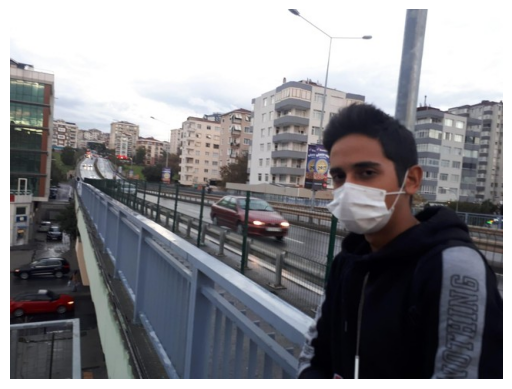

In [44]:
img = np.array(Image.open("../gun03/kucuk/foto_018.jpg"))  # siyah kareden kurtulmak için yeniden yükle

kirpik = img[100:400, 200:500].copy()
kirpik[:, :] = 0

plt.imshow(img)           # orijinal artık bozulmadı
plt.axis("off")
plt.show()

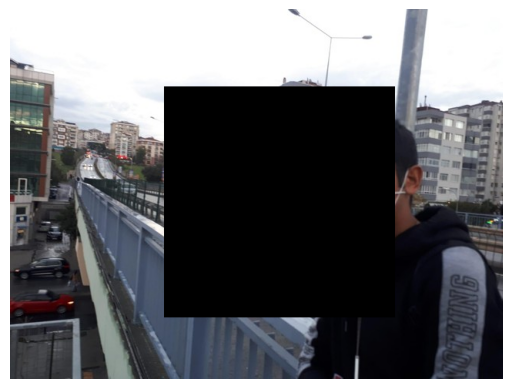

In [42]:
kirpik = img[100:400, 200:500]
kirpik[:, :] = 0          # kırpılmış parçayı tamamen siyah yap

plt.imshow(img)           # ORİJİNALİ gösteriyoruz
plt.axis("off")
plt.show()

(224, 224, 3)


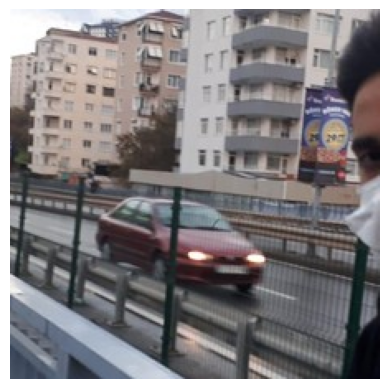

In [41]:
def merkezden_kirp(goruntu, boyut):
    yukseklik, genislik = goruntu.shape[:2]
    ust = (yukseklik - boyut) // 2
    sol = (genislik - boyut) // 2
    return goruntu[ust:ust + boyut, sol:sol + boyut]


kare = merkezden_kirp(img, 224)
print(kare.shape)

plt.imshow(kare)
plt.axis("off")
plt.show()

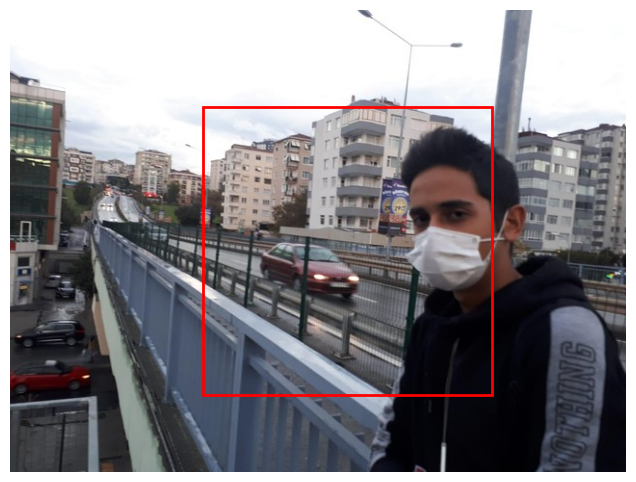

In [40]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img)

kutu = patches.Rectangle(
    (200, 100),       # sol üst köşe: (x, y) = (sütun, satır)
    300,              # genişlik
    300,              # yükseklik
    linewidth=2, edgecolor="red", facecolor="none"
)
ax.add_patch(kutu)
ax.axis("off")
plt.show()

Orijinal: (480, 640, 3)
Kırpılmış: (300, 300, 3)


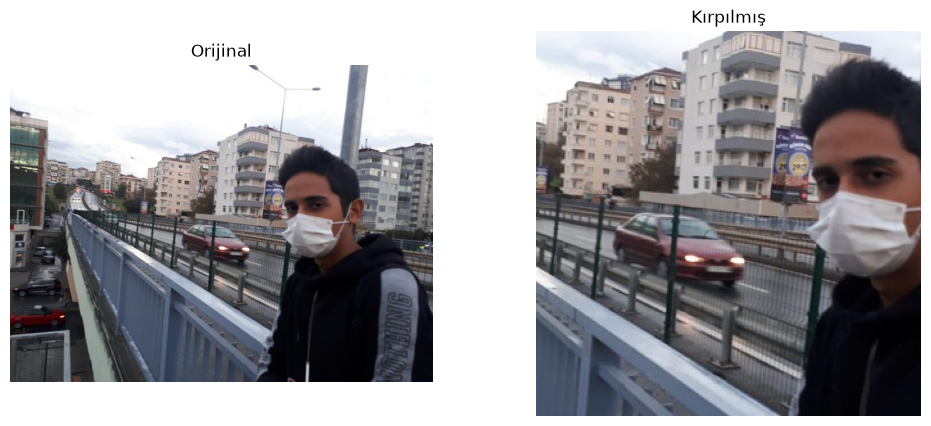

In [39]:
kirpik = img[100:400, 200:500]

print("Orijinal:", img.shape)
print("Kırpılmış:", kirpik.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img)
axes[0].set_title("Orijinal")
axes[1].imshow(kirpik)
axes[1].set_title("Kırpılmış")
for ax in axes:
    ax.axis("off")
plt.show()

In [25]:
pil_gri = np.array(Image.open("../gun03/kucuk/foto_018.jpg").convert("L"))

fark = np.abs(gri.astype(int) - pil_gri.astype(int))
print("En büyük fark:", fark.max())

En büyük fark: 0


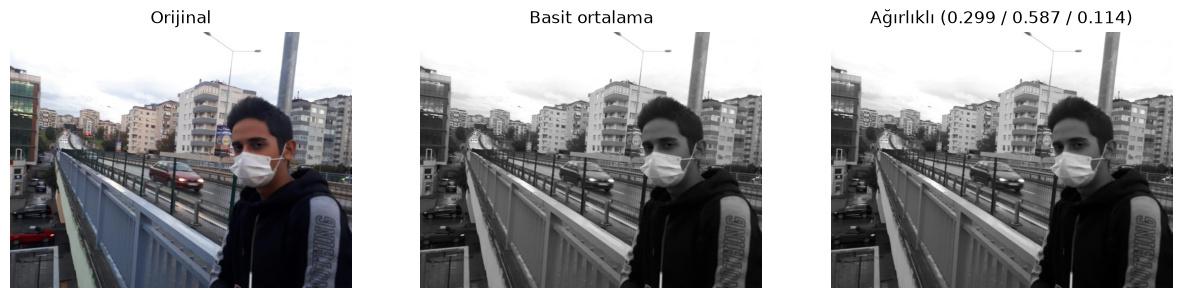

In [24]:
basit = img.mean(axis=2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img)
axes[0].set_title("Orijinal")

axes[1].imshow(basit, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Basit ortalama")

axes[2].imshow(gri, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Ağırlıklı (0.299 / 0.587 / 0.114)")

for ax in axes:
    ax.axis("off")

plt.show()

In [23]:
yesil = np.array([0, 255, 0])
mavi = np.array([0, 0, 255])

print("Basit ortalama  → yeşil:", yesil.mean(), " mavi:", mavi.mean())
print("Ağırlıklı       → yeşil:", 0.587 * 255, " mavi:", 0.114 * 255)

Basit ortalama  → yeşil: 85.0  mavi: 85.0
Ağırlıklı       → yeşil: 149.685  mavi: 29.07


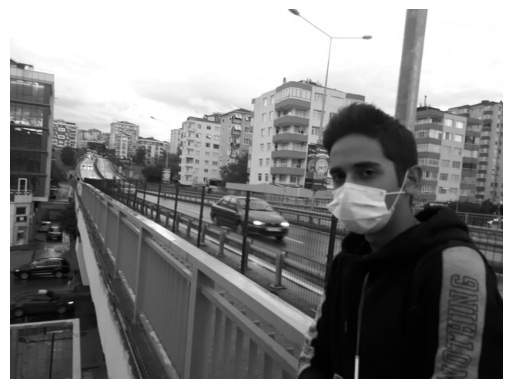

In [22]:
plt.imshow(gri, cmap="gray", vmin=0, vmax=255)
plt.axis('off')  # Eksenleri kapat
plt.show()

In [21]:
gri = gri.round().astype(np.uint8)  # Yuvarla ve uint8'e dönüştür
print("dtype:", gri.dtype)
print("Sol üst piksel:", gri[0, 0])

dtype: uint8
Sol üst piksel: 255


In [20]:
R = img[:, :, 0]
G = img[:, :, 1]
B = img[:, :, 2]

gri = R*0.299 + 0.587*G + 0.114*B
print("Orijinal shape:", img.shape)
print("Gri shape:", gri.shape)
print("Gri dtype:", gri.dtype)

Orijinal shape: (480, 640, 3)
Gri shape: (480, 640)
Gri dtype: float64


In [19]:
a = np.array([250], dtype=np.uint8)
print(a + 10)

[4]


(480, 640)


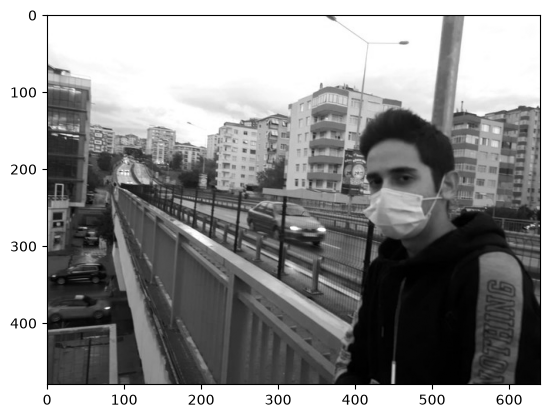

In [18]:
kirmizi = img[:, :, 0]  # Kırmızı kanal
print(kirmizi.shape)  # (yükseklik, genişlik)
plt.imshow(kirmizi, cmap="gray")
plt.show()

In [9]:
print("Boyut sayısı:", img.ndim)
print("Toplam sayı adedi:", img.size)
print("En küçük değer:", img.min())
print("En büyük değer:", img.max())
print("Ortalama parlaklık:", img.mean())

Boyut sayısı: 3
Toplam sayı adedi: 921600
En küçük değer: 0
En büyük değer: 255
Ortalama parlaklık: 125.87873589409722


In [8]:
print(img[0,0])  # İlk pikselin RGB değerlerini yazdır

[255 255 255]


In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
img = np.array(Image.open("../gun03/kucuk/foto_018.jpg"))

print("shape:", img.shape)
print("dtype:", img.dtype)

shape: (480, 640, 3)
dtype: uint8


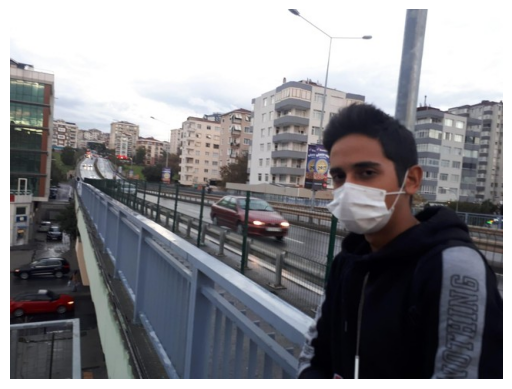

In [7]:
plt.imshow(img)
plt.axis('off')  # Eksenleri kapat
plt.show()